# Figure S9
### Definition of the 30 regions

In [1]:
import os
import geopandas as gp
import numpy as np
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import warnings
import colormaps as cmaps
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

In [2]:
regions_file = "/work10/archive/CMIP6/CMIP-SSPs/inputs/regionmasks/SSPs_30regions/SSPs_30regions_merged.shp"

# Load mask with 30 regions if it exists, otherwise create it
if os.path.exists(regions_file):
    regions = gp.read_file(regions_file)
else:
    regions = gp.read_file("/work10/archive/CMIP6/CMIP-SSPs/inputs/regionmasks/SSPs_30regions/SSPs_30regions.shp")
    regions = regions.dissolve(by='SSP_ID') # Merge regions with the same SSP_ID (35 regions -> 30 regions)
    regions = regions.reset_index()
    regions.to_file(regions_file)

print(f"✅ Loaded {regions.shape[0]} regions")

✅ Loaded 30 regions


In [3]:
def region_label_points(gdf, id_col="SSP_ID"):
    """Label anchor per region: a point guaranteed to lie inside the region's largest polygon part."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # area in degrees triggers a geographic-CRS warning
        parts = gdf[[id_col, "geometry"]].explode(index_parts=False).reset_index(drop=True)
        parts["area"] = parts.area
        largest = parts.loc[parts.groupby(id_col)["area"].idxmax()]
        pts = largest.geometry.representative_point()
    return {r: (p.x, p.y) for r, p in zip(largest[id_col], pts)}


def plot_region_map(gdf, title, id_col="SSP_ID", label_offsets=None, fontsize=10,
                    figsize=(16, 8.5), dpi=300, cmap=cmaps.cet_g_bw):
    """label_offsets: optional {region_id: (dlon, dlat)} to move crowded labels away from
    their anchor point; a thin leader line is drawn for displaced labels."""
    label_offsets = label_offsets or {}

    # One color per region: first N colors of the categorical palette, alphabetical order
    ids = sorted(gdf[id_col])
    colors = {r: cmap.colors[i] for i, r in enumerate(ids)}
    proj = ccrs.PlateCarree()

    fig = plt.figure(figsize=figsize, dpi=dpi)
    ax = plt.axes(projection=proj)
    gdf.plot(ax=ax, color=[colors[r] for r in gdf[id_col]],
             edgecolor="white", linewidth=0.3, transform=proj)
    ax.set_extent([-180, 180, -60, 90], crs=proj)

    ax.set_xticks(np.arange(-180, 181, 60), crs=proj)
    ax.set_yticks(np.arange(-60, 91, 30), crs=proj)
    ax.xaxis.set_major_formatter(LongitudeFormatter())
    ax.yaxis.set_major_formatter(LatitudeFormatter())
    ax.set_title(title, fontsize=22, fontweight="bold")

    # Region ID annotations: rounded box filled with the region's color
    for r, (x, y) in region_label_points(gdf, id_col).items():
        dx, dy = label_offsets.get(r, (0, 0))
        rgb = colors[r][:3]
        lum = 0.299 * rgb[0] + 0.587 * rgb[1] + 0.114 * rgb[2]
        ax.annotate(
            r, xy=(x, y), xytext=(x + dx, y + dy),
            ha="center", va="center", fontsize=fontsize, fontweight="bold",
            color="white" if lum < 0.5 else "black",   # readable text on any fill
            bbox=dict(boxstyle="round,pad=0.25", fc=rgb, ec="black", lw=0.8),
            arrowprops=dict(arrowstyle="-", lw=0.8, color="black") if (dx or dy) else None,
            zorder=5,
        )

    fig.tight_layout()
    return fig, ax

  ✓ png/Figures9.png
  ✓ pdf/Figures9.pdf


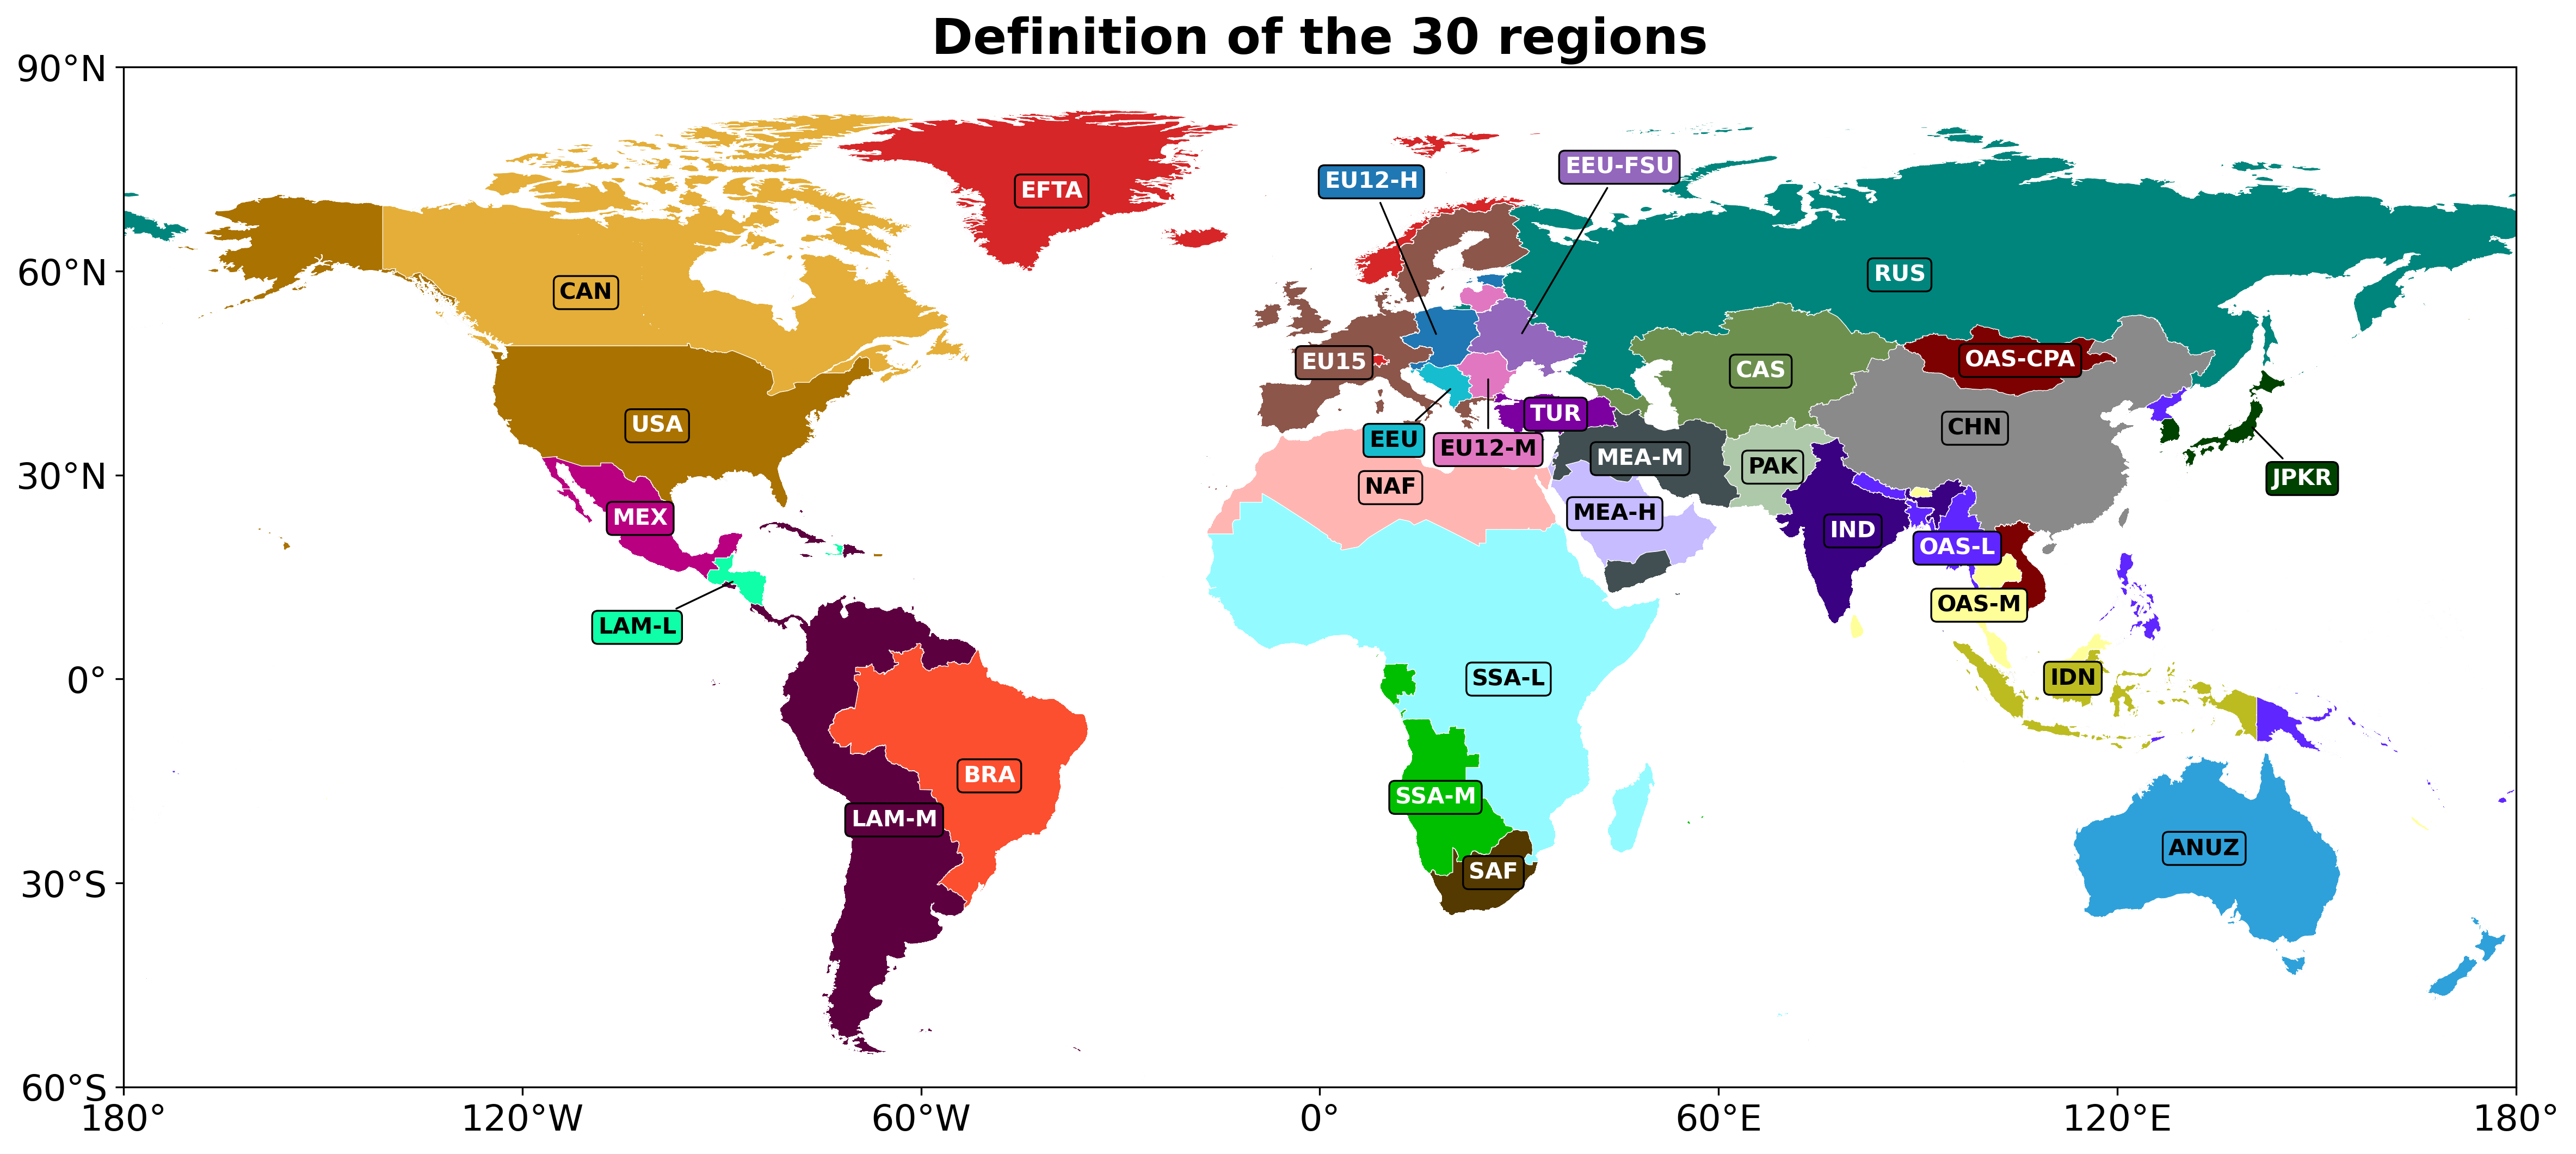

In [ ]:
# Style adjustments
plot_params = {
    "figure.dpi": 300,
    "font.size": 14,
    "axes.labelsize": "large",
    "axes.titlesize": 20,        # matches ax.set_title(..., fontsize=20) in end_of_century_maps_anom.py
    "figure.titlesize": "large",
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "legend.fontsize": 16,
}   
plt.rcParams.update(plot_params)

# Move region labels that don't fit inside region area
label_offsets = {
    "LAM-L":   (-15, -7),   # Central America -> Pacific, off the coast
    "EU12-H":  (-10, 23),   # Poland/Czechia area
    "EEU-FSU": (10, 25),    # Ukraine/Belarus area -> Barents/Kara Sea, right of EU12-H
    "EU12-M":  (0, -11),    # Romania/Bulgaria area -> eastern Mediterranean
    "EEU":     (-9, -8),    # Balkans -> central Mediterranean, left of EU12-M
    "JPKR":    (8, -8),    # Japan/Korea -> Pacific, east of Japan
}

fig, ax = plot_region_map(regions, title="Definition of the 30 regions",
                          cmap=cmaps.cet_g_hv, label_offsets=label_offsets)

# Save as png and pdf
for ext in ["png", "pdf"]:
        filename = f"{ext}/FigureS9.{ext}"
        fig.savefig(filename, dpi=500, bbox_inches="tight", pad_inches=0.3)
        print(f"  ✓ {filename}")

# Alt version: Legend below

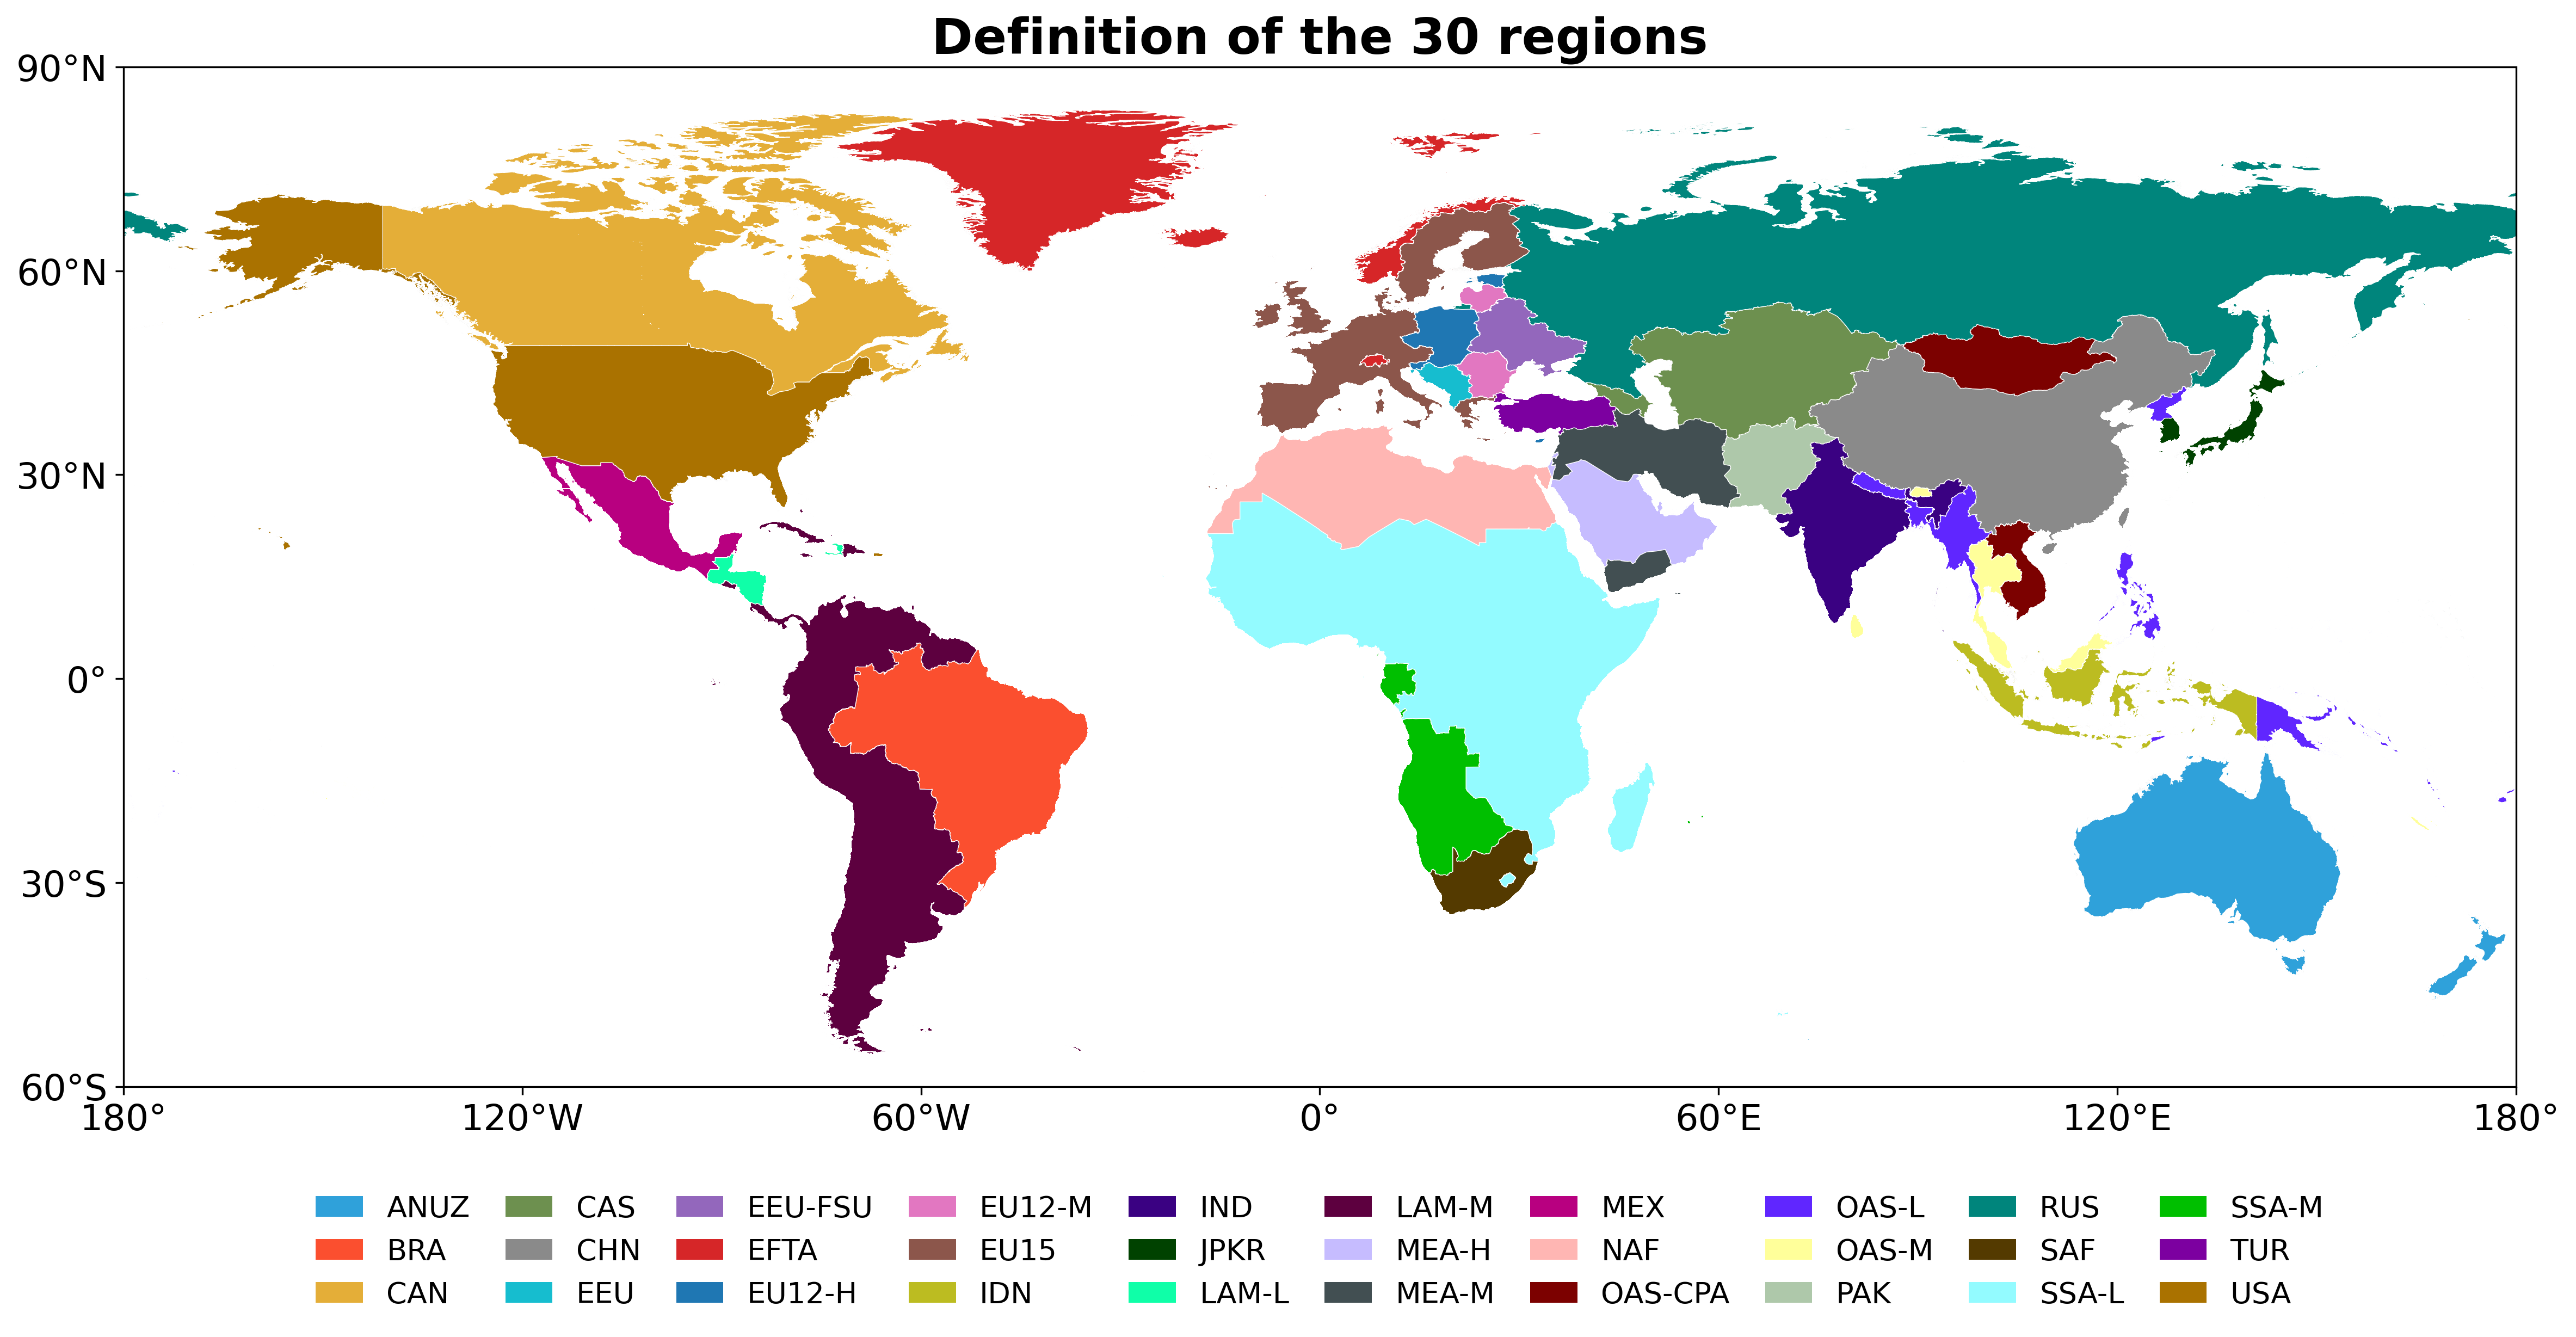

In [5]:
import colormaps as cmaps
from matplotlib.patches import Patch
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter


def plot_region_map(gdf, title, id_col="SSP_ID", 
                    figsize=(16, 8.5), dpi=300, cmap=cmaps.cet_g_bw):
    # One color per region: first N colors of the categorical palette, alphabetical order
    ids = sorted(gdf[id_col])
    colors = {r: cmap.colors[i] for i, r in enumerate(ids)}
    proj = ccrs.PlateCarree()

    fig = plt.figure(figsize=figsize, dpi=dpi)
    ax = plt.axes(projection=proj)
    gdf.plot(ax=ax, color=[colors[r] for r in gdf[id_col]],
             edgecolor="white", linewidth=0.3, transform=proj)
    ax.set_extent([-180, 180, -60, 90], crs=proj)

    ax.set_xticks(np.arange(-180, 181, 60), crs=proj)
    ax.set_yticks(np.arange(-60, 91, 30), crs=proj)
    ax.xaxis.set_major_formatter(LongitudeFormatter())
    ax.yaxis.set_major_formatter(LatitudeFormatter())
    ax.set_title(title, fontsize=22, fontweight="bold")

    handles = [Patch(facecolor=colors[r], edgecolor="none", label=r) for r in ids]
    ax.legend(handles=handles, ncol=10, loc="upper center", bbox_to_anchor=(0.5, -0.08),
              frameon=False, fontsize=13, handlelength=1.6, columnspacing=1.2)

    fig.tight_layout()
    return fig, ax


fig, ax = plot_region_map(regions, title="Definition of the 30 regions", cmap=cmaps.cet_g_hv)

# Save in current directory as png and pdf
# for ext in ["png", "pdf"]:
#         filename = f"{ext}/Figure4_bottom.{ext}"
#         fig.savefig(filename, dpi=500, bbox_inches="tight", pad_inches=0.3)
#         print(f"  ✓ {filename}")